# 2.5. Automatic Differentiation

In [1]:
import torch

## 2.5.1. A Simple Function

We're interested in differentiating $y = 2\mathbf{x}^\intercal\mathbf{x}$.

In [3]:
x = torch.arange(4.0)
x

tensor([0., 1., 2., 3.])

In [4]:
# Can also create x = torch.arange(4.0, requires_grad=True)
x.requires_grad_(True)
x.grad  # The gradient is None by default

In [5]:
y = 2 * torch.dot(x, x)
y

tensor(28., grad_fn=<MulBackward0>)

In [6]:
y.backward()
x.grad

tensor([ 0.,  4.,  8., 12.])

In [7]:
x.grad == 4 * x

tensor([True, True, True, True])

In [8]:
x.grad.zero_()  # Reset the gradient
y = x.sum()
y.backward()
x.grad

tensor([1., 1., 1., 1.])

## 2.5.2. Backward for Non-Scalar Variables

In [9]:
x.grad.zero_()
y = x * x
y.backward(gradient=torch.ones(len(y)))  # Faster: y.sum().backward()
x.grad

tensor([0., 2., 4., 6.])

## 2.5.3. Detaching Computation

In [11]:
x.grad.zero_()
y = x * x
u = y.detach()
z = u * x

z.sum().backward()
x.grad == u

tensor([True, True, True, True])

In [12]:
x.grad.zero_()
y.sum().backward()
x.grad == 2 * x

tensor([True, True, True, True])

## 2.5.4. Gradients and Python Control Flow

In [13]:
def f(a):
    b = a * 2
    while b.norm() < 1000:
        b = b * 2
    if b.sum() > 0:
        c = b
    else:
        c = 100 * b
    return c

In [22]:
a = torch.randn(size=(2,2), requires_grad=True)
d = f(a)
d.sum().backward()

In [23]:
a.grad == d / a

tensor([[True, True],
        [True, True]])

## 2.5.6. Exercises

In [33]:
from matplotlib import pyplot as plt

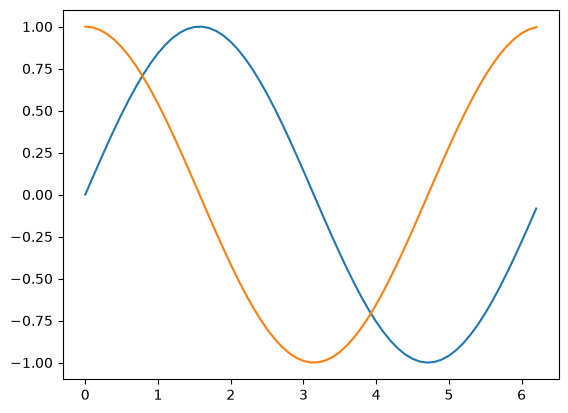

In [44]:
x = torch.arange(0, 2*torch.pi, 0.1, requires_grad=True)
y = torch.sin(x)
y.sum().backward()

xs = x.detach().numpy()
ys = y.detach().numpy()
yps = x.grad.numpy()

plt.plot(xs, ys, xs, yps)